# Sensitivity to K
Compare K=8, 10, 15, 20 and 25 with the selected K=12, using the current analysis data and the original LDA settings. Keep seed 42 fixed. This notebook checks how topic content changes with K; it does not calculate model-quality scores.

For each K=12 topic, find the most similar topic at each K using cosine similarity of full topic-word distributions. Topic numbers can change, and several K=12 topics can match the same smaller-K topic. Inspect the matched keyword lists before interpreting stability.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics.pairwise import cosine_similarity
import sklearn, gensim

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebook").is_dir() and (p / "data").is_dir())
output = project / "data" / "analysis_results" / "lda_k_sensitivity"
(project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
(project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
output.mkdir(parents=True, exist_ok=True)
ks = [8, 10, 12, 15, 20, 25]
titles = {"official_media": "Official Media", "weibo_posts": "Weibo Posts"}
colors = {"official_media": "#346d8c", "weibo_posts": "#c67c53"}
labels = pd.read_csv(project / "data" / "analysis_results" / "lda_k12_presentation" / "k12_topics_with_interpretations.csv")
plt.rcParams.update({"font.family": "Arial Unicode MS", "font.size": 11})


## 1. Fit the candidate K models
Use one vocabulary per corpus across K and verify every reconstructed keyword list against the existing LDA output. Verified fits are cached using a data and settings fingerprint.

In [2]:
def evaluate_corpus(corpus, min_df):
    source = project / "data" / f"{corpus}_analysis.csv"
    data = pd.read_csv(source, usecols=["tokens", "year"]).dropna(subset=["tokens"])
    vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                 min_df=min_df, max_df=0.85, max_features=5000)
    X = vectorizer.fit_transform(data["tokens"])
    keep = X.getnnz(axis=1) > 0
    X = X[keep]
    words = vectorizer.get_feature_names_out()
    settings = f"{ks}|{min_df}|0.85|5000|online|12|512|42|4|{sklearn.__version__}"
    signature = hashlib.sha256(source.read_bytes() + settings.encode()).hexdigest()
    cache_path = (project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")) / f"{corpus}_fits.npz"
    cached = {}
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as archive:
            if str(archive["signature"]) == signature:
                cached = {key: archive[key] for key in archive.files}
    fits, top_words = {}, {}
    arrays = {"signature": np.array(signature), "words": words.astype(str)}
    for k in ks:
        if f"beta_{k}" in cached:
            beta, prevalence = cached[f"beta_{k}"], cached[f"prevalence_{k}"]
        else:
            model = LatentDirichletAllocation(n_components=k, learning_method="online", max_iter=12,
                                             batch_size=512, random_state=42, n_jobs=4).fit(X)
            beta = model.components_ / model.components_.sum(axis=1, keepdims=True)
            prevalence = model.transform(X).mean(axis=0) * 100
        indices = beta.argsort(axis=1)[:, -10:][:, ::-1]
        top_words[k] = words[indices].tolist()
        original = pd.read_csv(project / "data" / "analysis_results" / f"lda_{corpus}" / f"k{k}_top10_keywords.csv")
        assert np.array_equal(words[indices], original.iloc[:, 1:].to_numpy()), "Saved topics differ."
        if k == 12:
            old = pd.read_csv(project / "data" / "analysis_results" / f"lda_{corpus}" / "k12_topic_prevalence.csv")
            assert np.allclose(prevalence, old["prevalence_pct"], atol=0.0051)
        fits[k] = {"beta": beta, "prevalence": prevalence, "indices": indices}
        arrays[f"beta_{k}"], arrays[f"prevalence_{k}"] = beta, prevalence
        print(f"{titles[corpus]}: K={k} verified.", flush=True)
    np.savez_compressed(cache_path, **arrays)
    return fits, top_words


In [3]:
official_fits, official_words = evaluate_corpus("official_media", 5)
weibo_fits, weibo_words = evaluate_corpus("weibo_posts", 10)


Official Media: K=8 verified.


Official Media: K=10 verified.


Official Media: K=12 verified.


Official Media: K=15 verified.


Official Media: K=20 verified.


...

Weibo Posts: K=10 verified.


Weibo Posts: K=12 verified.


Weibo Posts: K=15 verified.


Weibo Posts: K=20 verified.


Weibo Posts: K=25 verified.


## 2. Match topics across K
The K=12 self-comparison is 1 by definition. Report best-match cosine similarity and top-10 keyword overlap, as well as how often several reference topics share one match. The reverse average helps show when a larger-K model adds topics that do not closely resemble a K=12 topic.

In [4]:
matches, stability = [], []
for corpus, fits, topic_words in [("official_media", official_fits, official_words),
                                   ("weibo_posts", weibo_fits, weibo_words)]:
    baseline = fits[12]["beta"]
    names = labels[labels["corpus"] == corpus].set_index("topic")["interpretation"]
    for k in ks:
        similarity = cosine_similarity(baseline, fits[k]["beta"])
        best = similarity.argmax(axis=1)
        reuse = np.bincount(best, minlength=k)
        for t, target in enumerate(best):
            left, right = set(topic_words[12][t]), set(topic_words[k][target])
            matches.append({"corpus": corpus, "reference_topic": t + 1,
                "interpretation": names.loc[t + 1], "k": k, "matched_topic": target + 1,
                "cosine_similarity": similarity[t, target],
                "shared_top10_count": len(left & right), "top10_jaccard": len(left & right) / len(left | right),
                "reference_topics_sharing_target": reuse[target],
                "reference_top10": " / ".join(topic_words[12][t]),
                "matched_top10": " / ".join(topic_words[k][target])})
        stability.append({"corpus": corpus, "k": k,
            "mean_reference_to_k_similarity": similarity.max(axis=1).mean(),
            "min_reference_to_k_similarity": similarity.max(axis=1).min(),
            "mean_k_to_reference_similarity": similarity.max(axis=0).mean(),
            "distinct_matched_topics": len(set(best)), "total_topics_at_k": k})
matches = pd.DataFrame(matches)
stability = pd.DataFrame(stability)
matches.to_csv(output / "k12_topic_matches.csv", index=False, encoding="utf-8-sig")
stability.to_csv(output / "k_sensitivity_summary.csv", index=False, encoding="utf-8-sig")
assert np.allclose(matches.loc[matches["k"] == 12, "cosine_similarity"], 1)
display(stability.round(3))


,corpus,k,mean_reference_to_k_similarity,min_reference_to_k_similarity,mean_k_to_reference_similarity,distinct_matched_topics,total_topics_at_k
0,official_media,8,0.806,0.420,0.946,8,8
1,official_media,10,0.913,0.600,0.973,10,10
2,official_media,12,1.000,1.000,1.000,12,12
3,official_media,15,0.913,0.628,0.876,12,15
4,official_media,20,0.917,0.671,0.726,11,20
5,official_media,25,0.888,0.659,0.625,11,25
6,weibo_posts,8,0.706,0.465,0.768,8,8
7,weibo_posts,10,0.743,0.471,0.798,10,10
8,weibo_posts,12,1.000,1.000,1.000,12,12
9,weibo_posts,15,0.777,0.530,0.690,11,15


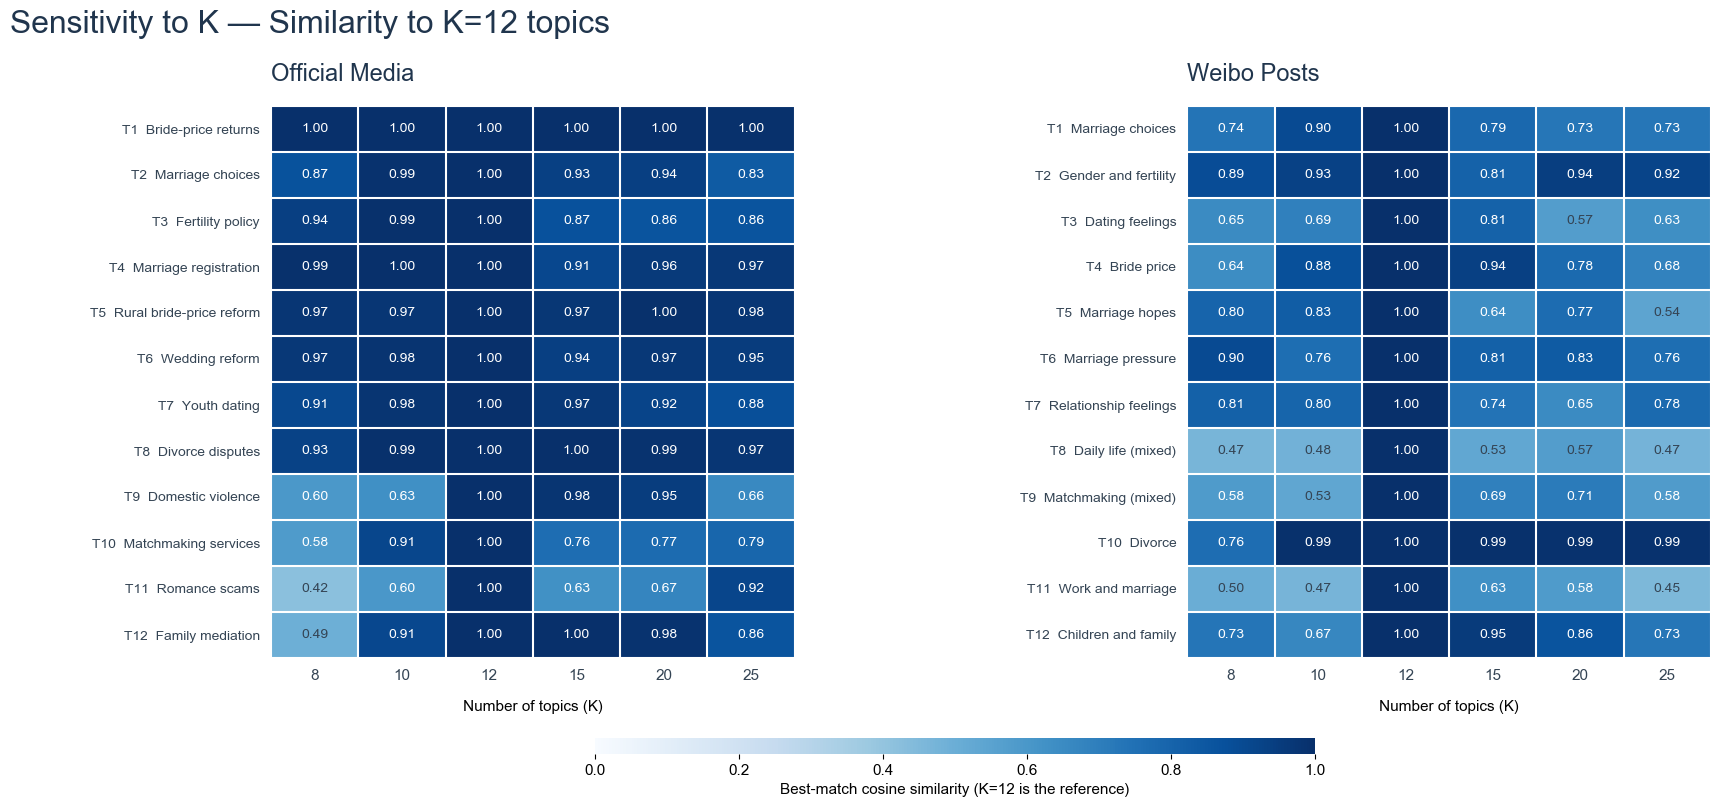

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), facecolor="white")
for ax, corpus in zip(axes, titles):
    data = matches[matches["corpus"] == corpus]
    matrix = data.pivot(index="reference_topic", columns="k", values="cosine_similarity").reindex(columns=ks)
    names = labels[labels["corpus"] == corpus].set_index("topic")["interpretation"]
    heat = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(ks)), ks)
    ax.set_yticks(range(12), [f"T{t}  {names.loc[t]}" for t in range(1, 13)], fontsize=10)
    ax.set_title(titles[corpus], loc="left", fontsize=17, fontweight="bold", color="#20354d", pad=18)
    ax.set_xlabel("Number of topics (K)", labelpad=12)
    ax.tick_params(length=0, pad=8, colors="#344454")
    ax.set_xticks(np.arange(-0.5, len(ks), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 12, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", length=0)
    for i in range(12):
        for j in range(len(ks)):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if value > 0.58 else "#344454")
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("Sensitivity to K — Similarity to K=12 topics", x=0.035, y=0.99,
             ha="left", fontsize=23, color="#20354d")
fig.subplots_adjust(left=0.18, right=0.98, top=0.87, bottom=0.18, wspace=0.75)
cax = fig.add_axes([0.36, 0.06, 0.40, 0.02])
bar = fig.colorbar(heat, cax=cax, orientation="horizontal")
bar.set_label("Best-match cosine similarity (K=12 is the reference)")
bar.outline.set_visible(False)
fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / "k_sensitivity.png", dpi=220, bbox_inches="tight")
plt.show()


## Reference
[Scikit-learn cosine similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html). These are single-seed, in-sample matches. A high cosine score alone does not prove that a topic has an identical substantive meaning.